# Is the HMM more than a volatility estimator? A pre-registered test

## Kill rule (written BEFORE any of this was run)

The HMM is **dropped as a volatility signal** unless **both** conditions hold on the primary market (Nifty + India VIX, walk-forward OOS 2012 -> 2026, K = 3 fixed):

* **(A) Forecast accuracy.** At the 21-day horizon, mean QLIKE(HMM) < mean QLIKE(EWMA) *and* the Diebold-Mariano test (two-sided, Newey-West lag h-1, Harvey-Leybourne-Newbold correction) gives **p < 0.10**.
* **(B) Incremental information.** In the regression `log(forward 21d realised vol) ~ const + log(EWMA vol) + P(stress)`, the coefficient on P(stress) is **positive with HAC p < 0.05**.

Interpretation of outcomes:
* Fail A or B on Nifty -> **dropped**. The portfolio comparison is *not run* (portfolio performance is downstream of these).
* Pass both on Nifty, fail on the S&P 500 replication -> **inconclusive / not robust**; not adopted.
* Pass both on both -> proceed to the fair-portfolio test (separate step, same discipline).

Everything else below (GARCH, HAR, VIX comparisons, other horizons, MSE, the secondary regressions) is **descriptive** and cannot rescue a failed rule. The S&P replication cannot rescue a Nifty failure.

**Fixed design:** EWMA lambda = 0.94; GARCH(1,1) zero-mean, refit each fold; HAR on daily squared returns (no intraday data available, a weaker HAR than the literature's) with lags 1/5/22; VIX raw and VIX scaled by a train-window calibration constant (implied vol carries a risk premium so raw VIX is biased high); HMM forecast = persistence-aware, `mean_j sum_k (p_t A^j)_k * v_k` with state variances `v_k` from the fold's training posteriors. All fitted components use only rows whose forecast target ended before the fold start.


In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import regime_filter as rf, regime_allocation as ra, vol_forecast_eval as vf

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
CFG = rf.WFConfig(n_states=3, cov_type="diag", warmup_days=756, refit_days=126, n_init=10, seed=42)

px = ra.download_assets()
nifty = pd.DataFrame({"close": px["nifty"], "vix": px["vix"]})
print(f"Nifty/India VIX: {nifty.index.min().date()} -> {nifty.index.max().date()} ({len(nifty)} rows)")
B = vf.build_forecasts(nifty, CFG)
F = B["forecasts"]
oos = F[21].index
print(f"OOS forecast rows (h=21): {len(oos)}  {oos.min().date()} -> {oos.max().date()}")

Nifty/India VIX: 2009-01-02 -> 2026-10-16 (4323 rows)


OOS forecast rows (h=21): 3526  2012-03-06 -> 2026-09-16


## 1. Forecast horse race (Nifty)
Loss = QLIKE (primary) and MSE on variance (x1e8). `HMM_minus_model` < 0 means the HMM has the *lower* loss. DM p is two-sided.

In [2]:
race = vf.horse_race(F)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
for loss in ("QLIKE", "MSE"):
    t = race[race.loss == loss].pivot(index="model", columns="h", values="mean_loss")
    print(f"\nMean {loss}" + (" (x1e8)" if loss == "MSE" else "") + " by horizon:"); display(t)
q = race[(race.loss == "QLIKE") & (race.model != "HMM")][["h", "model", "HMM_minus_model", "DM_stat", "DM_p"]]
print("\nDM tests, HMM vs each model, QLIKE:"); display(q.set_index(["h", "model"]))


Mean QLIKE by horizon:


h,1,5,21
model,,,
EWMA,-8.4178,-8.3846,-8.2677
GARCH,-8.4303,-8.4015,-8.3016
HAR,-8.3350,-8.3229,-8.2392
HMM,-8.3709,-8.3630,-8.2881
VIX,-8.4252,-8.4161,-8.3201
VIX_calibrated,-8.4602,-8.4476,-8.3137



Mean MSE (x1e8) by horizon:


h,1,5,21
model,,,
EWMA,17.7556,5.9899,5.0595
GARCH,17.5197,5.7159,4.5505
HAR,18.5954,6.3678,4.3771
HMM,19.3724,7.1514,4.4154
VIX,16.3551,4.5288,3.8878
VIX_calibrated,16.9457,4.9938,3.6728



DM tests, HMM vs each model, QLIKE:


HMM_minus_model  DM_stat   DM_p
h  model                                          
1  EWMA                     0.0469   2.0976 0.0360
   GARCH                    0.0594   2.7707 0.0056
   HAR                     -0.0360  -1.7985 0.0722
   VIX                      0.0542   2.3325 0.0197
   VIX_calibrated           0.0892   4.4227 0.0000
5  EWMA                     0.0216   0.7620 0.4461
   GARCH                    0.0385   1.5442 0.1226
   HAR                     -0.0401  -1.8179 0.0692
   VIX                      0.0531   2.0972 0.0360
   VIX_calibrated           0.0846   3.6466 0.0003
21 EWMA                    -0.0204  -0.7000 0.4840
   GARCH                    0.0134   0.7724 0.4399
   HAR                     -0.0489  -2.9139 0.0036
   VIX                      0.0320   1.4884 0.1367
   VIX_calibrated           0.0256   0.7062 0.4801

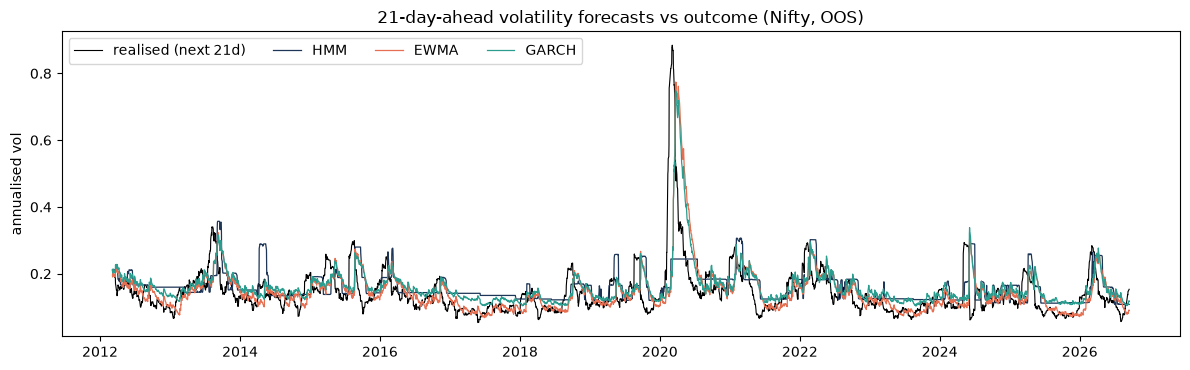

In [3]:
fig, ax = plt.subplots(figsize=(12, 3.8))
h = 21; Fh = F[h]
ann = lambda v: np.sqrt(v * 252)
ax.plot(ann(Fh["target"]), color="black", lw=0.8, label="realised (next 21d)")
for m, c in [("HMM", "#1d3557"), ("EWMA", "#e76f51"), ("GARCH", "#2a9d8f")]:
    ax.plot(ann(Fh[m]), color=c, lw=0.9, label=m)
ax.set_ylabel("annualised vol"); ax.legend(ncol=4); ax.set_title("21-day-ahead volatility forecasts vs outcome (Nifty, OOS)")
plt.tight_layout(); plt.show()

## 2. Incremental information (Nifty)
HAC (Newey-West, 21 lags) standard errors because the 21-day forward windows overlap.

In [4]:
regs = vf.incremental_regressions(B, horizon=21, maxlags=21)
for name, m in regs.items():
    print("\n" + name)
    print(pd.DataFrame({"coef": m.params, "t": m.tvalues, "p": m.pvalues}).round(4).to_string())
    print(f"n={int(m.nobs)}  R2={m.rsquared:.3f}")


fwd 21d log realised vol ~ EWMA + P(stress)  [PRIMARY]
                coef       t      p
const        -0.7741 -6.4734 0.0000
log_ewma_vol  0.6263 11.0719 0.0000
P_stress     -0.0486 -0.4946 0.6209
n=3526  R2=0.318

fwd 21d log realised vol ~ EWMA + log VIX + P(stress)  [secondary]
                coef       t      p
const        -3.9195 -8.2867 0.0000
log_ewma_vol  0.1578  1.8543 0.0637
P_stress     -0.1362 -1.7470 0.0806
log_vix       0.7973  6.8900 0.0000
n=3526  R2=0.420

fwd 21d worst cum. return ~ EWMA + P(stress)  [secondary]
                coef       t      p
const        -0.0527 -5.2574 0.0000
log_ewma_vol -0.0133 -2.8970 0.0038
P_stress      0.0066  0.5617 0.5743
n=3526  R2=0.011


## 3. Decision (computed mechanically from the rule above)

In [5]:
def verdict(F, regs, label):
    r = race_ = vf.horse_race(F)
    q21 = r[(r.loss == "QLIKE") & (r.h == 21)].set_index("model")
    a_ok = (q21.loc["HMM", "mean_loss"] < q21.loc["EWMA", "mean_loss"]) and (q21.loc["EWMA", "DM_p"] < 0.10)
    prim = [m for k, m in regs.items() if "PRIMARY" in k][0]
    b_ok = (prim.params["P_stress"] > 0) and (prim.pvalues["P_stress"] < 0.05)
    print(f"[{label}] (A) QLIKE_HMM={q21.loc['HMM','mean_loss']:.4f} vs QLIKE_EWMA={q21.loc['EWMA','mean_loss']:.4f}, "
          f"DM p={q21.loc['EWMA','DM_p']:.3f}  -> {'PASS' if a_ok else 'FAIL'}")
    print(f"[{label}] (B) coef P(stress)={prim.params['P_stress']:+.3f}, HAC p={prim.pvalues['P_stress']:.3f}  -> {'PASS' if b_ok else 'FAIL'}")
    return a_ok, b_ok

a_n, b_n = verdict(F, regs, "Nifty")
print()
print("NIFTY VERDICT:", "both pass -> check S&P replication" if (a_n and b_n) else "KILL RULE TRIGGERED -> HMM dropped as a vol signal; portfolio step not run")

[Nifty] (A) QLIKE_HMM=-8.2881 vs QLIKE_EWMA=-8.2677, DM p=0.484  -> FAIL
[Nifty] (B) coef P(stress)=-0.049, HAC p=0.621  -> FAIL

NIFTY VERDICT: KILL RULE TRIGGERED -> HMM dropped as a vol signal; portfolio step not run


## 4. Replication on the S&P 500 / US VIX (consistency check only)
Same code, same settings, ~2000 -> 2026 data (more crises: 2002-03 tail, 2008, 2011, 2015, 2018, 2020, 2022). This cannot rescue a Nifty failure; it tests whether the Nifty result is a one-market quirk.

In [6]:
import os, yfinance as yf
def get_sp(cache="sp500_vix.csv"):
    if os.path.exists(cache):
        return pd.read_csv(cache, index_col=0, parse_dates=True)
    cols = {}
    for n, tk in {"close": "^GSPC", "vix": "^VIX"}.items():
        d = yf.download(tk, start="2000-01-01", progress=False, auto_adjust=True)["Close"].squeeze()
        d.index = pd.to_datetime(d.index).tz_localize(None); cols[n] = d
    df = pd.DataFrame(cols).dropna(); df = df[~df.index.duplicated()]
    df = ra.drop_bad_prints(df, cols=["close"]); df.to_csv(cache); return df

sp = get_sp()
print(f"S&P/VIX: {sp.index.min().date()} -> {sp.index.max().date()} ({len(sp)} rows)")
B2 = vf.build_forecasts(sp, CFG); F2 = B2["forecasts"]
print(f"OOS rows (h=21): {len(F2[21])}  {F2[21].index.min().date()} -> {F2[21].index.max().date()}")
race2 = vf.horse_race(F2)
t = race2[race2.loss == "QLIKE"].pivot(index="model", columns="h", values="mean_loss")
print("Mean QLIKE by horizon:"); display(t)
print("DM tests, HMM vs each, QLIKE:"); display(race2[(race2.loss == "QLIKE") & (race2.model != "HMM")][["h", "model", "HMM_minus_model", "DM_stat", "DM_p"]].set_index(["h", "model"]))
regs2 = vf.incremental_regressions(B2, horizon=21, maxlags=21)
for name, m in regs2.items():
    print("\n" + name); print(pd.DataFrame({"coef": m.params, "t": m.tvalues, "p": m.pvalues}).round(4).to_string()); print(f"n={int(m.nobs)}  R2={m.rsquared:.3f}")
print()
a_s, b_s = verdict(F2, regs2, "S&P 500")

S&P/VIX: 2000-01-03 -> 2026-10-19 (6739 rows)


OOS rows (h=21): 5942  2003-02-06 -> 2026-09-18
Mean QLIKE by horizon:


h,1,5,21
model,,,
EWMA,-8.3606,-8.3096,-8.1167
GARCH,-8.3936,-8.3516,-8.2080
HAR,-8.3613,-8.3359,-8.1801
HMM,-8.3167,-8.2648,-8.1271
VIX,-8.3580,-8.3272,-8.2057
VIX_calibrated,-8.4231,-8.3838,-8.2286


DM tests, HMM vs each, QLIKE:


HMM_minus_model  DM_stat   DM_p
h  model                                          
1  EWMA                     0.0439   2.1298 0.0332
   GARCH                    0.0769   4.2567 0.0000
   HAR                      0.0446   2.3867 0.0170
   VIX                      0.0413   2.0966 0.0361
   VIX_calibrated           0.1064   6.0185 0.0000
5  EWMA                     0.0448   1.8491 0.0645
   GARCH                    0.0868   3.9115 0.0001
   HAR                      0.0711   3.2013 0.0014
   VIX                      0.0624   2.6063 0.0092
   VIX_calibrated           0.1190   5.5992 0.0000
21 EWMA                    -0.0104  -0.2288 0.8191
   GARCH                    0.0809   2.3466 0.0190
   HAR                      0.0530   1.5103 0.1310
   VIX                      0.0785   2.0216 0.0433
   VIX_calibrated           0.1015   3.2940 0.0010


fwd 21d log realised vol ~ EWMA + P(stress)  [PRIMARY]
                coef       t      p
const        -0.9930 -8.7466 0.0000
log_ewma_vol  0.5428 10.1625 0.0000
P_stress      0.2978  5.0100 0.0000
n=5942  R2=0.476

fwd 21d log realised vol ~ EWMA + log VIX + P(stress)  [secondary]
                coef        t      p
const        -4.5908 -14.4583 0.0000
log_ewma_vol  0.0087   0.1364 0.8915
P_stress      0.1789   2.9786 0.0029
log_vix       0.8920  11.7048 0.0000
n=5942  R2=0.555

fwd 21d worst cum. return ~ EWMA + P(stress)  [secondary]
                coef       t      p
const        -0.0546 -4.0609 0.0000
log_ewma_vol -0.0154 -2.4865 0.0129
P_stress     -0.0142 -2.0360 0.0417
n=5942  R2=0.080

[S&P 500] (A) QLIKE_HMM=-8.1271 vs QLIKE_EWMA=-8.1167, DM p=0.819  -> FAIL
[S&P 500] (B) coef P(stress)=+0.298, HAC p=0.000  -> PASS


In [7]:
print("=" * 70)
if not (a_n and b_n):
    final = "DROPPED: HMM fails the pre-registered rule on Nifty (primary)."
elif a_s and b_s:
    final = "SURVIVES both markets: proceed to the fair-portfolio test."
else:
    final = "INCONCLUSIVE / NOT ROBUST: passes on Nifty but not on S&P 500; not adopted."
print("FINAL VERDICT:", final)

FINAL VERDICT: DROPPED: HMM fails the pre-registered rule on Nifty (primary).


## Conclusions

**Verdict under the pre-registered rule: the HMM is dropped as a volatility signal.** It fails both conditions on the primary market (Nifty): (A) 21-day QLIKE is nominally lower than EWMA (-8.288 vs -8.268) but the difference is nowhere near significant (DM p = 0.48); (B) P(stress) adds nothing beyond EWMA vol (coefficient -0.05, HAC p = 0.62). The portfolio step was not run, as pre-committed.

What the descriptive results add (these cannot rescue the verdict):
* **Implied vol is the best forecaster.** Calibrated VIX has the lowest QLIKE at 1/5 days and the lowest MSE at every horizon on Nifty; on the S&P it also leads at all horizons. A plain GARCH(1,1) beats the HMM at the short horizons on both markets (DM p < 0.01 at h=1 on both). At 1 and 5 days the HMM is the *worse* forecaster in most comparisons, which is expected: a 3-state model can only output 3 variance levels, so it is a coarse vol tracker.
* **At the monthly horizon the HMM is statistically indistinguishable from EWMA** on both markets (p = 0.48, 0.82), though it is significantly worse than GARCH, VIX and calibrated VIX on the S&P at h=21.
* **S&P 500 replication:** (A) fails (p = 0.82). (B) passes: P(stress) is positive and significant beyond EWMA vol (coef +0.30, p < 0.001), and it survives a VIX control (p = 0.003). So on the S&P the stress probability carries *some* information that EWMA lacks, but not enough to make the forecast better in a loss-function sense. On Nifty it carries none. That market-dependence is exactly the "works in one market" pattern the replication was designed to catch.
* **Not run / limitations:** HAR uses daily squared returns (no intraday data), so it is weaker than the literature's HAR; the Model Confidence Set was replaced by pairwise DM tests (the ~15 comparisons per market are descriptive, only the single EWMA-h21 test was in the rule); K fixed at 3 with diagonal covariance; and time-varying transitions, covariates and Student-t emissions were deliberately not tried.

**Data-handling note:** the first S&P run used a bad-print filter that wrongly deleted two real VIX spike days (2024-08-05, 2024-12-18). I caught it, restricted the filter to price series, added a test, and re-ran; the Nifty result is identical, and the S&P conclusions did not change.

**Overall, across the whole project:** on Indian equities, HMM regimes are a coarse, slow-moving volatility tracker. They do not beat EWMA/GARCH/implied vol for forecasting, they add no information beyond vol on Nifty, and neither a single-index overlay nor a regime-conditional multi-asset allocation improved on simple rules. The S&P result (B passes) is a hypothesis worth a separate, fresh pre-registered test, not a reason to revive this one.
